[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Time-Series-Analysis/blob/main/notebooks/EN/chapter14_seminar_notebook.ipynb)

# Time Series Analysis — Seminar 14: Multivariate GARCH models (CCC, DCC, BEKK) and portfolio VaR

*Seminar notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

- Chapter 14 is a self-study chapter: read it first; the slides recap the formulas used here.
- [Solved] tasks: full solution here and in the slides; [Proposed] tasks: write your own code in the empty cell.
- The seminar is for practice and is not graded; the solutions of [Proposed] tasks are discussed in class.
- The first code cell installs the `arch` package if it is missing (otherwise a numpy fallback is used).

> The solutions are discussed in the seminar.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/TSA/Chapter_14'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


In [ ]:
# The arch package (step 1: univariate GARCH) is not preinstalled in Google Colab: pip install arch
# (without it, garch11_fit falls back to a numpy maximum-likelihood estimator)
import importlib.util, subprocess, sys
if importlib.util.find_spec('arch') is None:
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
    except Exception as e:
        print('arch not installed, the numpy fallback will be used:', e)

In [ ]:
import os
import re
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from scipy import optimize
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

## Chart style

- Transparent background, legend below the plot, course palette.

In [ ]:
# Palette (RGB values of latex/preamble.tex)
MainBlue = '#1A3A6E'
IDAred = '#CD0000'
Forest = '#2E7D32'
Amber = '#B5853F'
Orange = '#E67E22'
Purple = '#8E44AD'
Teal = '#17A2B8'
Crimson = '#DC3545'
DarkText = '#1F2A44'          # text, axes and ticks (dark navy, not grey)

PALETTE = [MainBlue, IDAred, Forest, Amber, Purple, Orange, Teal, Crimson]
# fixed colours for the series used in several chapters
COL = {'sp500': MainBlue, 'bet': IDAred, 'bettr': Orange, 'dax': Teal, 'btc': Amber, 'eth': Crimson,
       'eurron': Forest, 'gold': Purple, 'vix': Crimson, 'stoxx50': Forest, 'ndx': Teal}


def apply():
    """Set the course style for matplotlib."""
    rc = plt.rcParams
    rc['figure.facecolor'] = 'none'
    rc['axes.facecolor'] = 'none'
    rc['savefig.facecolor'] = 'none'
    rc['savefig.transparent'] = True
    rc['axes.grid'] = False
    rc['font.family'] = 'sans-serif'
    rc['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
    # default size about 7 inches wide (as in MFM); a chart is shown 11-13 cm wide on a slide, so these font sizes
    # give 7-9 pt text there. Multi-panel charts should stay near 7-7.6 inches wide: at 10-11 inches the axis
    # text drops to about 5 pt on the slide.
    rc['figure.figsize'] = (7.0, 3.4)
    rc['font.size'] = 12
    rc['axes.labelsize'] = 13
    rc['axes.titlesize'] = 13
    rc['xtick.labelsize'] = 11.5
    rc['ytick.labelsize'] = 11.5
    rc['legend.fontsize'] = 11
    rc['axes.spines.top'] = False
    rc['axes.spines.right'] = False
    rc['axes.linewidth'] = 0.6
    rc['lines.linewidth'] = 1.4
    rc['legend.facecolor'] = 'none'
    rc['legend.framealpha'] = 0
    rc['legend.frameon'] = False
    for k in ('text.color', 'axes.labelcolor', 'axes.edgecolor', 'xtick.color', 'ytick.color', 'axes.titlecolor'):
        rc[k] = DarkText
    rc['axes.prop_cycle'] = mpl.cycler(color=PALETTE)
    _remember_tight_layout()


def _remember_tight_layout():
    """Figure.tight_layout also stores its arguments on the figure, so that save_fig can re-apply the same layout
    after it has wrapped a label or changed the number of legend columns (see finalize)."""
    from matplotlib.figure import Figure
    if getattr(Figure.tight_layout, '_tsa', False):
        return
    orig = Figure.tight_layout

    def tight_layout(self, *a, **k):
        self._tsa_tight = (a, k)
        return orig(self, *a, **k)
    tight_layout._tsa = True
    Figure.tight_layout = tight_layout


def legend_outside_bottom(ax, ncol=2, y=-0.22, **kw):
    """Place the legend outside the plot, bottom centre (for a figure with several axes, pass the last one
    or use fig.legend with the same arguments)."""
    return ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False, **kw)


def fig_legend_bottom(fig, handles=None, labels=None, ncol=3, y=-0.02):
    """One legend for a whole figure (several panels), below the panels."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels and not l.startswith('_'):
                    handles.append(h)
                    labels.append(l)
    return fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def _is_grey(c, tol=0.06):
    try:
        r, g, b = to_rgb(c)
    except ValueError:
        return False
    return max(r, g, b) - min(r, g, b) < tol and 0.25 < (r + g + b) / 3 < 0.95


def check_no_grey(fig):
    """House rule: no grey series and no grey text. Raises ValueError listing the offending elements."""
    bad = []
    for ax in fig.axes:
        for ln in ax.get_lines():
            if not ln.get_label().startswith('_') and _is_grey(ln.get_color()):
                bad.append(f'line {ln.get_label()!r}')
        for coll in ax.collections:
            fc = coll.get_facecolor()
            if len(fc) and coll.get_label() and not coll.get_label().startswith('_') and _is_grey(fc[0][:3]):
                bad.append(f'series {coll.get_label()!r}')
        for t in ax.texts + [ax.title, ax.xaxis.label, ax.yaxis.label]:
            if t.get_text() and _is_grey(t.get_color()):
                bad.append(f'text {t.get_text()[:30]!r}')
    if bad:
        raise ValueError('grey elements: ' + ', '.join(bad))


def save_fig(name, out_dir=None, show=True):
    """Save the figure as transparent PDF and PNG (OUT_DIR if defined, else the current folder), then show it."""
    d = out_dir or globals().get('OUT_DIR', '.')
    plt.savefig(os.path.join(d, f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(d, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    if show:
        plt.show()
    plt.close()


apply()
# the chapter scripts call the style as st.<name> (import tsa_style as st): the same names here
import types
st = types.SimpleNamespace(COL=COL, PALETTE=PALETTE, MainBlue=MainBlue, IDAred=IDAred, Forest=Forest, Amber=Amber,
                           Orange=Orange, Purple=Purple, Teal=Teal, Crimson=Crimson, DarkText=DarkText, apply=apply, legend_outside_bottom=legend_outside_bottom,
                           fig_legend_bottom=fig_legend_bottom, save_fig=save_fig, check_no_grey=check_no_grey)

## Data

- Daily market data from EODHD, saved in `data/market` of the TSA repository; EUR/RON is the official BNR reference rate.
- Macroeconomic series: FRED (St. Louis Fed), Eurostat and the classic data sets of statsmodels.
- Returns in %: $r_t = 100(\ln P_t - \ln P_{t-1})$; each series on its own calendar.

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Time-Series-Analysis/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'          # last day of the saved data

# name -> (symbol, label, group, field, default start)
SERIES = {
    # equity indices
    'sp500':    ('GSPC.INDX',     'S&P 500',               'Equity', 'close', '2000-01-01'),
    'ndx':      ('NDX.INDX',      'Nasdaq 100',            'Equity', 'close', '2000-01-01'),
    'dax':      ('GDAXI.INDX',    'DAX',                   'Equity', 'close', '2000-01-01'),
    'stoxx50':  ('STOXX50E.INDX', 'Euro Stoxx 50',         'Equity', 'close', '2000-01-01'),
    'nikkei':   ('N225.INDX',     'Nikkei 225',            'Equity', 'close', '2000-01-01'),
    'bet':      ('BET',           'BET',                   'Equity', 'close', '2000-01-01'),
    'bettr':    ('BETTR.INDX',    'BET-TR',                'Equity', 'close', '2014-09-23'),
    'betxt':    ('BETXT.INDX',    'BET-XT',                'Equity', 'close', '2011-08-12'),
    'betfi':    ('BETFI.INDX',    'BET-FI',                'Equity', 'close', '2012-01-25'),
    'wig20':    ('WIG20.INDX',    'WIG20',                 'Equity', 'close', '2000-01-01'),
    'bux':      ('BUX.INDX',      'BUX',                   'Equity', 'close', '2000-01-01'),
    'px':       ('PX.INDX',       'PX',                    'Equity', 'close', '2000-01-01'),
    'vix':      ('VIX.INDX',      'VIX',                   'Volatility', 'close', '2000-01-01'),
    # ETFs (adjusted close)
    'spy':      ('SPY.US',        'SPY',                   'ETF', 'adjusted_close', '2000-01-01'),
    'tlt':      ('TLT.US',        'TLT (US Treasuries 20y+)', 'ETF', 'adjusted_close', '2002-07-30'),
    'gld':      ('GLD.US',        'GLD (gold ETF)',        'ETF', 'adjusted_close', '2004-11-18'),
    'tvbetetf': ('TVBETETF.RO',   'TVBETETF',              'ETF', 'adjusted_close', '2015-06-12'),
    # Bucharest Stock Exchange (adjusted close)
    'tlv':      ('TLV.RO',        'Banca Transilvania',    'Stock', 'adjusted_close', '2000-01-01'),
    'snp':      ('SNP.RO',        'OMV Petrom',            'Stock', 'adjusted_close', '2001-09-04'),
    'brd':      ('BRD.RO',        'BRD',                   'Stock', 'adjusted_close', '2001-01-16'),
    'tgn':      ('TGN.RO',        'Transgaz',              'Stock', 'adjusted_close', '2008-01-25'),
    'sng':      ('SNG.RO',        'Romgaz',                'Stock', 'adjusted_close', '2013-11-12'),
    'snn':      ('SNN.RO',        'Nuclearelectrica',      'Stock', 'adjusted_close', '2013-11-04'),
    'h2o':      ('H2O.RO',        'Hidroelectrica',        'Stock', 'adjusted_close', '2023-07-12'),
    # US stocks (adjusted close)
    'aapl':     ('AAPL.US',       'Apple',                 'Stock', 'adjusted_close', '2000-01-01'),
    'msft':     ('MSFT.US',       'Microsoft',             'Stock', 'adjusted_close', '2000-01-01'),
    'nvda':     ('NVDA.US',       'NVIDIA',                'Stock', 'adjusted_close', '2000-01-01'),
    'jpm':      ('JPM.US',        'JPMorgan Chase',        'Stock', 'adjusted_close', '2000-01-01'),
    # crypto (close, 7 days a week)
    'btc':      ('BTC-USD.CC',    'Bitcoin',               'Crypto', 'close', '2014-09-17'),
    'eth':      ('ETH-USD.CC',    'Ethereum',              'Crypto', 'close', '2015-08-07'),
    'sol':      ('SOL-USD.CC',    'Solana',                'Crypto', 'close', '2020-04-11'),
    'usdt':     ('USDT-USD.CC',   'Tether (USDT)',         'Crypto', 'close', '2015-02-26'),
    # FX and commodities
    'eurron':   ('REF:EUR',       'EUR/RON (BNR reference)', 'FX', 'close', '2005-07-01'),
    'usdron':   ('REF:USD',       'USD/RON (BNR reference)', 'FX', 'close', '2005-07-01'),
    'eurron_eodhd': ('EURRON.FOREX', 'EUR/RON (EODHD)',    'FX', 'close', '2005-07-01'),
    'eurusd':   ('EURUSD.FOREX',  'EUR/USD',               'FX', 'close', '2002-05-06'),
    'gold':     ('XAUUSD.FOREX',  'Gold (XAU/USD)',        'Commodity', 'close', '2000-01-01'),
    # government bond yields (close, % p.a.)
    'us10y':    ('US10Y.GBOND',   'US 10Y yield',          'Yield', 'close', '2000-01-01'),
    'de10y':    ('DE10Y.GBOND',   'Germany 10Y yield',     'Yield', 'close', '2007-03-28'),
    'ro10y':    ('RO10Y.GBOND',   'Romania 10Y yield',     'Yield', 'close', '2007-08-17'),
}
LABELS = {k: v[1] for k, v in SERIES.items()}
_CACHE = {}


def read_market(symbol):
    """Daily table of one symbol: local copy of the course data, otherwise the TSA repository on GitHub."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname) if MARKET_DIR else ''
    src = path if path and os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end=END):
    """Official BNR reference rate (RON per unit of currency), from the public yearly XML archives."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(max(int(start[:4]), 2005), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}"(?: multiplier="\d+")?>([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_close(name, start=None, end=END, field=None):
    """Daily closing price of a named series, cleaned with the course conventions."""
    symbol, label, group, field0, start0 = SERIES[name]
    start, field = start or start0, field or field0
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start, end=end).rename(name)
    t = read_market(symbol)
    s = (t[field] if field in t.columns else t['close']).loc[start:end]
    s = pd.to_numeric(s, errors='coerce').dropna()
    if group != 'Yield':
        s = s[s > 0]
    if group != 'Crypto':
        s = s[s.index.dayofweek < 5]          # no weekend quotes
        s = s[s.diff() != 0]                  # no holidays filled with the previous price
    s.index.name = 'date'
    return s.rename(name)


def load_ohlc(name, start=None, end=END):
    """Open, high, low, close (and volume) of a series with OHLC data (range-based volatility estimators)."""
    symbol, _, group, _, start0 = SERIES[name]
    t = read_market(symbol).loc[start or start0:end]
    cols = [c for c in ('open', 'high', 'low', 'close', 'volume') if c in t.columns]
    t = t[cols].dropna()
    if group != 'Crypto':
        t = t[t.index.dayofweek < 5]
    return t[(t[['open', 'high', 'low', 'close']] > 0).all(axis=1)] if 'open' in cols else t


def log_returns(name, start=None, end=END, pct=True):
    """Daily log returns r_t = ln P_t - ln P_{t-1} (in % by default), on the series' own calendar."""
    r = np.log(load_close(name, start, end)).diff().dropna()
    return (100 * r if pct else r).rename(name)


def simple_returns(name, start=None, end=END, pct=True):
    """Daily simple returns R_t = P_t / P_{t-1} - 1 (in % by default)."""
    r = load_close(name, start, end).pct_change().dropna()
    return (100 * r if pct else r).rename(name)


def load_panel(names, start=None, end=END, kind='close'):
    """Several series aligned on date: kind = 'close' or 'returns' (NaN where a market does not trade)."""
    f = load_close if kind == 'close' else log_returns
    return pd.concat([f(n, start, end) for n in names], axis=1)


def periods_per_year(r):
    """Average number of observations per calendar year (the actual frequency of the series)."""
    years = (r.index[-1] - r.index[0]).days / 365.25
    return len(r) / years


def read_fred(ids, start=None, end=None):
    """FRED series (St. Louis Fed) from the public fredgraph CSV, e.g. read_fred('UNRATE') or
    read_fred(['GDPC1', 'CPIAUCSL']). Returns a Series (one id) or a DataFrame (several ids)."""
    one = isinstance(ids, str)
    ids = [ids] if one else list(ids)
    out = []
    for sid in ids:
        key = ('fred', sid)
        if key not in _CACHE:
            url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}'
            t = pd.read_csv(url, index_col=0, parse_dates=True, na_values='.')
            _CACHE[key] = pd.to_numeric(t.iloc[:, 0], errors='coerce').rename(sid)
        out.append(_CACHE[key])
    df = pd.concat(out, axis=1).loc[start:end]
    df.index.name = 'date'
    return df.iloc[:, 0].dropna() if one else df


def _eurostat_period(p):
    p = str(p)
    if '-Q' in p:
        y, q = p.split('-Q')
        return pd.Timestamp(int(y), 3 * int(q) - 2, 1)
    if '-' in p and len(p) == 7:
        return pd.Timestamp(p + '-01')
    if len(p) == 4:
        return pd.Timestamp(int(p), 1, 1)
    return pd.Timestamp(p)


def read_eurostat(dataset, key, start=None):
    """One Eurostat series from the public SDMX 2.1 API (SDMX-CSV), e.g. Romanian quarterly real GDP,
    seasonally and calendar adjusted, chain-linked volumes (2010) in million EUR:
        read_eurostat('namq_10_gdp', 'Q.CLV10_MEUR.SCA.B1GQ.RO')
    `key` is the dot-separated series key of the dataset (dimensions in the order of the dataset)."""
    url = (f'https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/{dataset}/{key}?format=SDMX-CSV'
           + (f'&startPeriod={start}' if start else ''))
    ck = ('eurostat', url)
    if ck not in _CACHE:
        t = pd.read_csv(url)
        s = pd.Series(pd.to_numeric(t['OBS_VALUE'], errors='coerce').values,
                      index=[_eurostat_period(p) for p in t['TIME_PERIOD']], name=f'{dataset}:{key}')
        s.index.name = 'date'
        _CACHE[ck] = s.sort_index().dropna()
    return _CACHE[ck]


def load_statsmodels(name):
    """Classic data sets shipped with statsmodels (offline): 'sunspots' (yearly, 1700-2008), 'co2' (weekly,
    Mauna Loa, 1958-2001), 'macrodata' (US quarterly macro, 1959-2009), 'nile' (yearly Nile flow, 1871-1970)."""
    import statsmodels.api as sm
    if name == 'sunspots':
        d = sm.datasets.sunspots.load_pandas().data
        s = d.set_index(pd.to_datetime(d['YEAR'].astype(int).astype(str)))['SUNACTIVITY']
        s.index.name = 'date'
        return s.rename('sunspots')
    if name == 'co2':
        return sm.datasets.co2.load_pandas().data['co2'].rename('co2')
    if name == 'macrodata':
        d = sm.datasets.macrodata.load_pandas().data
        d.index = pd.period_range('1959Q1', periods=len(d), freq='Q').to_timestamp()
        d.index.name = 'date'
        return d
    if name == 'nile':
        d = sm.datasets.nile.load_pandas().data
        s = d.set_index(pd.to_datetime(d['year'].astype(int).astype(str)))['volume']
        s.index.name = 'date'
        return s.rename('nile')
    raise KeyError(f'unknown statsmodels data set: {name}')

## Seminar functions

- Helpers of Chapter 14 (`common_returns`, `step1`, `dcc_fit`, `dcc_path`, `half_life`, `kupiec`, `christoffersen`) and the seminar functions: `dcc_Q`, `sp_dax`, `a1_dcc_step`, `a3_portfolio`, `a5_half_life`, `b1_stock_bond`.

In [ ]:
from scipy.signal import lfilter
NAME = {'sp500': 'S&P 500', 'dax': 'DAX', 'bet': 'BET', 'eurron': 'EUR/RON', 'btc': 'Bitcoin'}
PANEL = ['sp500', 'dax', 'bet', 'eurron', 'btc']
PANEL_START = '2015-01-01'
PAIR_START = '2000-01-01'
HEDGE_START = '2005-01-01'
SPLIT = '2014-12-31'
ROLL = 250
ALPHA_VAR = 0.01
WEIGHTS = (0.5, 0.5)
CRISES = {'2008': ('2008-09-15', '2009-03-31'), '2020': ('2020-02-20', '2020-04-30')}
CALM = ('2017-01-01', '2019-12-31')
PANEL_CRISIS = ('2020-02-14', '2020-06-30')
EX = {'s1': 20.0, 's2': 20.0, 'rhos': (0.2, 0.8), 'a': 0.05, 'b': 0.93, 'qbar': 0.5, 'q11': 1.0, 'q22': 1.0, 'q12': 0.5, 'z': (-2.0, -2.5), 'var_s': (1.5, 1.2), 'var_rho': (0.3, 0.9), 'h_ss': 1.2, 'h_sf': 1.0, 'h_rho': 0.8, 'bk': {'c12': 0.02, 'a11': 0.3, 'a22': 0.25, 'b11': 0.94, 'b22': 0.95, 'e': (-2.0, -1.5), 'h12': 0.5}}
COLORS = {'sp500': st.MainBlue, 'dax': st.Teal, 'bet': st.IDAred, 'eurron': st.Forest, 'btc': st.Amber}
HERE = next((p for p in ("../../Quantlets/Ch_14", "Quantlets/Ch_14", ".") if os.path.isdir(p)), ".")
SHOCK_DAY = '2020-03-17'
HEDGE_DAY = '2026-09-18'
BOND_START = '2003-01-01'
BOND_BREAK = '2022-01-01'
VAR_PAIR = ('bet', 'dax')
VAR_W = (0.5, 0.5)
BEKK_EX = {'c11': 0.05, 'c12': 0.01, 'c22': 0.04, 'a11': 0.25, 'a22': 0.3, 'b11': 0.95, 'b22': 0.93, 'e': (1.5, -1.0), 'h11': 1.2, 'h12': 0.3, 'h22': 0.9}
HL_STEPS = (10, 50)


def save(name, save_it=True):
    if save_it:
        st.check_no_grey(plt.gcf())
        st.save_fig(name)
    else:
        plt.show()


def shade(ax, periods=CRISES, alpha=0.15):
    for i, (a, b) in enumerate(periods.values()):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=st.Crimson, alpha=alpha, lw=0,
                   label='Crisis periods (2008, 2020)' if i == 0 else None)


def common_returns(names, start, end=None):
    """Daily log returns in % computed on the days on which ALL markets trade: prices are aligned first, so each
    return covers the same calendar interval for every series."""
    P = pd.concat([load_close(k, start) for k in names], axis=1, join='inner')
    if end:
        P = P.loc[:end]
    return (100 * np.log(P).diff()).dropna()


def weekly_returns(names, start=PANEL_START):
    """Weekly log returns in % (Friday closes, or the last close of the week): the weekly horizon removes most of the
    asynchronous-trading problem of markets that close at different hours (New York, Frankfurt, Bucharest, crypto)."""
    P = pd.concat([load_close(k, start).resample('W-FRI').last() for k in names], axis=1).dropna()
    return (100 * np.log(P).diff()).dropna()


def garch11_negloglik(theta, r):
    """Gaussian negative log-likelihood of r_t = mu + e_t, sigma2_t = omega + alpha e_{t-1}^2 + beta sigma2_{t-1}."""
    mu, omega, alpha, beta = theta
    if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 0.9999:
        return 1e10
    e = r - mu
    s2 = garch11_variance(e, omega, alpha, beta)
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(s2) + e ** 2 / s2)


def garch11_variance(e, omega, alpha, beta, s0=None):
    """sigma2_t = omega + alpha e_{t-1}^2 + beta sigma2_{t-1}, started at the sample variance (one-step-ahead:
    sigma2_t uses only e_1, ..., e_{t-1})."""
    x = np.empty(len(e))
    x[0] = np.var(e) if s0 is None else s0
    x[1:] = omega + alpha * e[:-1] ** 2
    # sigma2_t - beta sigma2_{t-1} = x_t  -> a linear filter
    out = lfilter([1.0], [1.0, -beta], x)
    return out


def garch11_fit(r):
    """Step 1 of DCC: GARCH(1,1) with a constant mean, Gaussian QML. The arch package if installed, else a numpy
    maximum-likelihood fallback (the two give practically the same estimates)."""
    r = np.asarray(r, float)
    try:
        from arch import arch_model
        res = arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='normal').fit(disp='off')
        p = res.params
        return dict(mu=float(p['mu']), omega=float(p['omega']), alpha=float(p['alpha[1]']), beta=float(p['beta[1]']))
    except ImportError:
        v = np.var(r)
        best = optimize.minimize(garch11_negloglik, [r.mean(), 0.05 * v, 0.08, 0.90], args=(r,), method='Nelder-Mead',
                                 options=dict(maxiter=4000, xatol=1e-8, fatol=1e-8))
        mu, omega, alpha, beta = best.x
        return dict(mu=float(mu), omega=float(omega), alpha=float(alpha), beta=float(beta))


def garch11_filter(r, p, s0=None):
    """Conditional volatility (one step ahead) and standardised residuals z_t = (r_t - mu) / sigma_t for given
    parameters p (from garch11_fit), on any sample (also out of sample)."""
    e = np.asarray(r, float) - p['mu']
    s2 = garch11_variance(e, p['omega'], p['alpha'], p['beta'], s0)
    s = np.sqrt(s2)
    return s, e / s


def step1(R, fit_until=None):
    """GARCH(1,1) for every column of R (estimated on R.loc[:fit_until]); volatilities and residuals on all of R."""
    P, S, Z = {}, {}, {}
    for c in R.columns:
        x = R[c].loc[:fit_until] if fit_until else R[c]
        P[c] = garch11_fit(x.values)
        s0 = float(np.var(x.values - P[c]['mu']))
        S[c], Z[c] = garch11_filter(R[c].values, P[c], s0)
    return P, pd.DataFrame(S, index=R.index), pd.DataFrame(Z, index=R.index)


def dcc_path(Z, a, b, Qbar=None):
    """Correlation matrices R_t (T x N x N), one step ahead (R_t uses z_1, ..., z_{t-1}). Every element of Q_t follows
    the same linear recursion, computed with scipy's lfilter."""
    X = np.asarray(Z, float)
    T, N = X.shape
    Qbar = np.corrcoef(X.T) if Qbar is None else Qbar
    P = np.einsum('ti,tj->tij', X, X)                       # z_t z_t'
    drive = np.empty_like(P)
    drive[0] = Qbar
    drive[1:] = (1 - a - b) * Qbar + a * P[:-1]
    Q = lfilter([1.0], [1.0, -b], drive.reshape(T, -1), axis=0).reshape(T, N, N)
    Q[0] = Qbar
    d = np.sqrt(np.einsum('tii->ti', Q))
    return Q / (d[:, :, None] * d[:, None, :])


def dcc_loglik(Z, a, b, Qbar=None):
    """Correlation part of the Gaussian log-likelihood: -1/2 sum_t (log|R_t| + z_t' R_t^{-1} z_t - z_t' z_t)."""
    X = np.asarray(Z, float)
    R = dcc_path(X, a, b, Qbar)
    _, logdet = np.linalg.slogdet(R)
    quad = np.einsum('ti,tij,tj->t', X, np.linalg.inv(R), X)
    return float(-0.5 * np.sum(logdet + quad - np.sum(X ** 2, axis=1)))


def num_hessian(f, x, h=1e-4):
    k = len(x)
    H = np.zeros((k, k))
    E = np.eye(k) * h
    for i in range(k):
        for j in range(k):
            H[i, j] = (f(x + E[i] + E[j]) - f(x + E[i] - E[j]) - f(x - E[i] + E[j]) + f(x - E[i] - E[j])) / (4 * h * h)
    return H


def dcc_fit(Z):
    """Step 2: (a, b) by maximum likelihood with Qbar fixed at the sample correlation of z (correlation targeting).
    Standard errors from the step-2 Hessian (they ignore the estimation error of step 1). CCC: a = b = 0."""
    X = np.asarray(Z, float)
    Qbar = np.corrcoef(X.T)

    def nll(p):
        a, b = p
        if a < 0 or b < 0 or a + b >= 0.9999:
            return 1e10
        return -dcc_loglik(X, a, b, Qbar)

    best = None
    for s in ((0.03, 0.95), (0.01, 0.98), (0.05, 0.90), (0.10, 0.80)):
        r = optimize.minimize(nll, s, method='Nelder-Mead', options=dict(xatol=1e-7, fatol=1e-7, maxiter=4000))
        if best is None or r.fun < best.fun:
            best = r
    a, b = best.x
    try:
        se = np.sqrt(np.diag(np.linalg.inv(num_hessian(nll, best.x))))
    except Exception:
        se = np.array([np.nan, np.nan])
    ll, ll0 = -best.fun, dcc_loglik(X, 0.0, 0.0, Qbar)
    return dict(a=float(a), b=float(b), se_a=float(se[0]), se_b=float(se[1]), loglik=float(ll), ccc_loglik=float(ll0),
                lr=float(2 * (ll - ll0)), Qbar=Qbar)


def half_life(p):
    return float(np.log(0.5) / np.log(p))


def kupiec(viol, alpha=ALPHA_VAR):
    """Kupiec (1995) unconditional coverage test: LR = -2 log[(1-a)^(n-x) a^x / ((1-p)^(n-x) p^x)], chi2(1)."""
    n, x = len(viol), int(np.sum(viol))
    p = x / n
    l0 = (n - x) * np.log(1 - alpha) + x * np.log(alpha)
    l1 = (n - x) * np.log(1 - p) + (x * np.log(p) if x > 0 else 0.0)
    lr = -2 * (l0 - l1)
    return dict(n=n, x=x, rate=p, lr=float(lr), p=float(stats.chi2.sf(lr, 1)))


def christoffersen(viol):
    """Christoffersen (1998) independence test: does a violation today make a violation tomorrow more likely?
    LR = -2 log[L(pi) / L(pi01, pi11)], chi2(1)."""
    v = np.asarray(viol, int)
    a, b = v[:-1], v[1:]
    n00, n01 = np.sum((a == 0) & (b == 0)), np.sum((a == 0) & (b == 1))
    n10, n11 = np.sum((a == 1) & (b == 0)), np.sum((a == 1) & (b == 1))
    p01, p11 = n01 / max(n00 + n01, 1), n11 / max(n10 + n11, 1)
    p = (n01 + n11) / len(a)
    xl = lambda k, q: k * np.log(q) if k > 0 else 0.0
    l0 = xl(n00 + n10, 1 - p) + xl(n01 + n11, p)
    l1 = xl(n00, 1 - p01) + xl(n01, p01) + xl(n10, 1 - p11) + xl(n11, p11)
    lr = -2 * (l0 - l1)
    return dict(n11=int(n11), p01=float(p01), p11=float(p11), lr=float(lr), p=float(stats.chi2.sf(lr, 1)))


def lecture_numbers():
    """The numbers of Chapter 14 (generate_all_charts.py): local copy, else the copy on GitHub."""
    path = os.path.join(HERE, 'ch14_numbers.json')
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    import urllib.request
    url = 'https://raw.githubusercontent.com/danpele/Time-Series-Analysis/main/Quantlets/Ch_14/ch14_numbers.json'
    return json.loads(urllib.request.urlopen(url).read())


def dcc_Q(Z, a, b, Qbar):
    """The matrices Q_t of the DCC recursion (the same recursion as dcc_path, written as a loop)."""
    X = np.asarray(Z, float)
    Q = np.empty((len(X), X.shape[1], X.shape[1]))
    Q[0] = Qbar
    for t in range(1, len(X)):
        Q[t] = (1 - a - b) * Qbar + a * np.outer(X[t - 1], X[t - 1]) + b * Q[t - 1]
    return Q


def sp_dax():
    R = common_returns(['sp500', 'dax'], PAIR_START)
    P, S, Z = step1(R)
    f = dcc_fit(Z.values)
    return R, P, S, Z, f


def a1_dcc_step(data=None, day=SHOCK_DAY):
    """A1: Q_t = (1 - a - b) Qbar + a z_{t-1} z_{t-1}' + b Q_{t-1} for the S&P 500 and the DAX on `day`."""
    R, P, S, Z, f = data or sp_dax()
    a, b, Qbar = f['a'], f['b'], f['Qbar']
    Q = dcc_Q(Z.values, a, b, Qbar)
    Rt = dcc_path(Z.values, a, b, Qbar)
    t = R.index.get_loc(pd.Timestamp(day))
    z1, z2 = Z.values[t - 1]
    Qp, Qn = Q[t - 1], Q[t]
    c = 1 - a - b
    rho = Qn[0, 1] / np.sqrt(Qn[0, 0] * Qn[1, 1])
    assert abs(rho - Rt[t, 0, 1]) < 1e-10
    return dict(day=day, prev=str(R.index[t - 1].date()), a=a, b=b, c=c, qbar=float(Qbar[0, 1]), z1=float(z1), z2=float(z2),
                r1=float(R.values[t - 1, 0]), r2=float(R.values[t - 1, 1]),
                q11p=float(Qp[0, 0]), q22p=float(Qp[1, 1]), q12p=float(Qp[0, 1]),
                rho_prev=float(Qp[0, 1] / np.sqrt(Qp[0, 0] * Qp[1, 1])),
                t1=float(c * Qbar[0, 1]), t2=float(a * z1 * z2), t3=float(b * Qp[0, 1]),
                t11=(float(c), float(a * z1 * z1), float(b * Qp[0, 0])), t22=(float(c), float(a * z2 * z2), float(b * Qp[1, 1])),
                q11=float(Qn[0, 0]), q22=float(Qn[1, 1]), q12=float(Qn[0, 1]), rho=float(rho),
                rho_next=float(Rt[t + 1, 0, 1]), se_a=f['se_a'], se_b=f['se_b'], ab=a + b, n=len(R))


def a3_portfolio(data=None, day=SHOCK_DAY, w=(0.5, 0.5)):
    """A3: H_t = D_t R_t D_t with the GARCH volatilities of `day`, the DCC correlation (A1) and the constant CCC
    correlation; portfolio variance w' H_t w and VaR 1% = -(mu_p + z_0.01 sigma_p); a static covariance matrix."""
    R, P, S, Z, f = data or sp_dax()
    Rt = dcc_path(Z.values, f['a'], f['b'], f['Qbar'])
    t = R.index.get_loc(pd.Timestamp(day))
    s1, s2 = S.values[t]
    w = np.array(w)
    mu = float(w @ np.array([P[k]['mu'] for k in R.columns]))
    zq = float(stats.norm.ppf(ALPHA_VAR))
    out = dict(day=day, s1=float(s1), s2=float(s2), mu=mu, z=zq, w1=float(w[0]), w2=float(w[1]),
               s1_ann=float(s1 * np.sqrt(252)), s2_ann=float(s2 * np.sqrt(252)))
    C = np.cov(R.values.T)
    for k, rho in (('dcc', Rt[t, 0, 1]), ('ccc', f['Qbar'][0, 1]), ('static', C[0, 1] / np.sqrt(C[0, 0] * C[1, 1]))):
        if k == 'static':
            a1, a2 = np.sqrt(C[0, 0]), np.sqrt(C[1, 1])
        else:
            a1, a2 = s1, s2
        H = np.array([[a1 ** 2, rho * a1 * a2], [rho * a1 * a2, a2 ** 2]])
        v = float(w @ H @ w)
        out[k] = dict(rho=float(rho), h11=float(H[0, 0]), h22=float(H[1, 1]), h12=float(H[0, 1]), var=v, sd=float(np.sqrt(v)),
                      VaR=float(-(mu + zq * np.sqrt(v))), s1=float(a1), s2=float(a2),
                      t1=float(w[0] ** 2 * H[0, 0]), t2=float(w[1] ** 2 * H[1, 1]), t3=float(2 * w[0] * w[1] * H[0, 1]))
    out['ret'] = float(R.values[t] @ w)
    out['r1'], out['r2'] = float(R.values[t, 0]), float(R.values[t, 1])
    return out


def a5_half_life(a1=None, b1=None, steps=HL_STEPS):
    """A5: half-life ln 0.5 / ln(a + b) of a correlation shock and the approximate forecast
    rho_{t+k} ~ rho_bar + (a + b)^k (rho_t - rho_bar), for the S&P 500 and DAX (A1), the five-asset panel of the lecture
    and the stock-bond pair of B1."""
    N = lecture_numbers()
    a1 = a1 or a1_dcc_step()
    out = {'spdax': dict(ab=a1['ab'], hl=half_life(a1['ab']), d90=float(np.log(0.1) / np.log(a1['ab'])))}
    out['panel'] = dict(ab=N['panel']['ab'], hl=half_life(N['panel']['ab']), d90=float(np.log(0.1) / np.log(N['panel']['ab'])))
    if b1:
        out['bond'] = dict(ab=b1['ab'], hl=half_life(b1['ab']), d90=float(np.log(0.1) / np.log(b1['ab'])))
    out['fc'] = {str(k): float(a1['qbar'] + a1['ab'] ** k * (a1['rho'] - a1['qbar'])) for k in steps}
    out['rho'], out['qbar'] = a1['rho'], a1['qbar']
    out['ab_ccc'] = 0.0
    return out


def b1_stock_bond(save_it=True):
    """B1: DCC of the S&P 500 and TLT (long US Treasuries), daily since 2003: parameters, likelihood ratio against
    CCC (a = b = 0), half-life, the correlation before and after 2022; chart against the 250-day rolling correlation."""
    R = common_returns(['sp500', 'tlt'], BOND_START)
    P, S, Z = step1(R)
    f = dcc_fit(Z.values)
    Rt = dcc_path(Z.values, f['a'], f['b'], f['Qbar'])
    rho = pd.Series(Rt[:, 0, 1], index=R.index)
    roll = R['sp500'].rolling(ROLL).corr(R['tlt'])
    fig, ax = plt.subplots(figsize=(9.33, 2.75))
    ax.plot(rho.index, rho, color=st.IDAred, lw=0.7, label='DCC correlation')
    ax.plot(roll.index, roll, color=st.MainBlue, lw=1.4, label='Rolling correlation (250 days)')
    ax.axhline(f['Qbar'][0, 1], color=st.Forest, ls='--', lw=1.3, label='CCC (constant) correlation')
    ax.axhline(0, color=st.DarkText, lw=0.6, ls=':')
    ax.axvline(pd.Timestamp(BOND_BREAK), color=st.Purple, ls='-.', lw=1.0, label='January 2022')
    ax.set_ylabel('Correlation, S&P 500 and TLT')
    st.legend_outside_bottom(ax, ncol=4)
    save('ch14_sem_b1', save_it)
    pre, post = rho.loc[:'2021-12-31'], rho.loc[BOND_BREAK:]
    lr = 2 * (f['loglik'] - f['ccc_loglik'])
    return dict(n=len(R), first=str(R.index[0].date()), last=str(R.index[-1].date()), a=f['a'], b=f['b'], se_a=f['se_a'],
                se_b=f['se_b'], ab=f['a'] + f['b'], hl=half_life(f['a'] + f['b']), lr=float(lr),
                crit=float(stats.chi2.ppf(0.95, 2)), p=float(stats.chi2.sf(lr, 2)), qbar=float(f['Qbar'][0, 1]),
                rcorr=float(R.corr().iloc[0, 1]), mean_pre=float(pre.mean()), mean_post=float(post.mean()),
                pos_pre=float((pre > 0).mean()), pos_post=float((post > 0).mean()), min=float(rho.min()),
                dmin=str(rho.idxmin().date()), max=float(rho.max()), dmax=str(rho.idxmax().date()), rho_last=float(rho.iloc[-1]),
                garch={k: dict(P[k], pers=P[k]['alpha'] + P[k]['beta']) for k in R.columns})

# Part A: computations on paper

- Do each computation on paper first; then check it with the code. A1, A3 and A5 use the S&P 500 and DAX DCC estimated on 2000-2026: the next cell estimates it once.

In [ ]:
data = sp_dax()        # daily S&P 500 and DAX on common trading days: GARCH(1,1) per index, then the DCC

## A1 [Solved]: one step of the DCC recursion

**Context.** The DCC of the S&P 500 and the DAX; the residuals $z$ of 16 March 2020 and $Q_{t-1}$.

1. Compute $q_{11}$, $q_{22}$, $q_{12}$ for 17 March 2020, term by term.
2. Compute the correlation of 16 and of 17 March 2020.
3. Why does a fall of 12% move the correlation so little?

**Report:** three elements of $Q_t$, two correlations, one sentence.

In [9]:
# Solution
a1 = a1_dcc_step(data)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in a1.items()})

{'day': '2020-03-17', 'prev': '2020-03-16', 'a': 0.0152, 'b': 0.9766, 'c': 0.0082, 'qbar': 0.5748, 'z1': -2.2741, 'z2': -1.1818, 'r1': -12.7652, 'r2': -5.4517, 'q11p': 1.5509, 'q22p': 1.7093, 'q12p': 1.1471, 'rho_prev': 0.7045, 't1': 0.0047, 't2': 0.0409, 't3': 1.1202, 't11': (0.008156268847210879, 0.07876792208545544, 1.5146722147439833), 't22': (0.008156268847210879, 0.021272339974832237, 1.6693031789989465), 'q11': 1.6016, 'q22': 1.6987, 'q12': 1.1659, 'rho': 0.7068, 'rho_next': 0.7067, 'se_a': 0.0035, 'se_b': 0.0065, 'ab': 0.9918, 'n': 6605}


**Interpretation of the result.** $b$ is close to 1 and the GARCH-standardised residuals are moderate, so the correlation moves from 0.705 to 0.707 only.

## A2 [Proposed]: one step of a diagonal BEKK

**Context.** $c_{11} = 0.05$, $c_{12} = 0.01$, $c_{22} = 0.04$; $a_{11} = 0.25$, $a_{22} = 0.30$; $b_{11} = 0.95$, $b_{22} = 0.93$; $\varepsilon_{t-1} = (1.5, -1.0)$; $h_{11} = 1.2$, $h_{12} = 0.3$, $h_{22} = 0.9$. Model: A1.

1. Compute $h_{11,t}$, $h_{22,t}$, $h_{12,t}$ term by term.
2. Compute the correlation at $t - 1$ and at $t$. Why does it fall?
3. Check that $H_t$ is positive definite; give the persistences.

**Report:** three elements, two correlations, one determinant, three persistences.

In [ ]:
# Your code here


## A3 [Solved]: portfolio variance and VaR under CCC and DCC

**Context.** S&P 500 and DAX on 17 March 2020: GARCH volatilities, the DCC correlation of A1, the constant CCC correlation and a static covariance matrix; weights (0.5, 0.5).

1. Compute $h_{12} = \rho_{12}\sigma_1\sigma_2$ for each model.
2. Compute $\sigma_p^2 = w^\top Hw$, $\sigma_p$ and the VaR 1% for each model.
3. Which part of the VaR comes from the correlation, which from the volatilities?

**Report:** three covariances, three VaRs, one sentence.

In [11]:
# Solution
a3 = a3_portfolio(data)
print(pd.DataFrame({k: a3[k] for k in ('dcc', 'ccc', 'static')}).round(3))
print('portfolio return that day:', round(a3['ret'], 2))

        dcc     ccc  static
rho   0.707   0.575   0.599
h11  47.447  47.447   1.490
h22  22.347  22.347   2.042
h12  23.016  18.718   1.045
var  28.956  26.808   1.405
sd    5.381   5.178   1.186
VaR  12.453  11.980   2.693
s1    6.888   6.888   1.221
s2    4.727   4.727   1.429
t1   11.862  11.862   0.373
t2    5.587   5.587   0.510
t3   11.508   9.359   0.522
portfolio return that day: 4.02


**Interpretation of the result.** The volatilities move the VaR from about 2.7% (static) to 12% (CCC); the crisis correlation adds about half a point (DCC).

## A4 [Proposed]: the hedge ratio of the BET with the DAX

**Context.** DCC of the BET and the DAX estimated on 2005-2014 (Chapter 14), run to 18 September 2026. Model: A3.

1. Compute $h_t = \rho_t\sigma_{s,t}/\sigma_{f,t}$ and the DAX position for 100 lei of BET.
2. Compute $\rho_t^2$ and $\sigma_s\sqrt{1 - \rho_t^2}$.
3. Compare with the static OLS ratio and with the out-of-sample effectiveness of the lecture.

**Report:** two ratios, one position, two effectiveness figures, one sentence.

In [ ]:
# Your code here


## A5 [Solved]: the half-life of a correlation shock

**Context.** $a + b$ of the S&P 500 and DAX (A1), of the five-asset panel of the lecture and of the stock-bond pair (B1).

1. Compute the half-life $\ln 0.5/\ln(a + b)$ and $\ln 0.1/\ln(a + b)$.
2. Forecast the S&P 500 and DAX correlation 10 and 50 days after 17 March 2020 with $\rho_{t+k} \approx \bar\rho + (a + b)^k(\rho_t - \bar\rho)$.
3. What is the half-life under CCC?

**Report:** six durations, two forecasts, one sentence. (B1 is estimated in the next cell.)

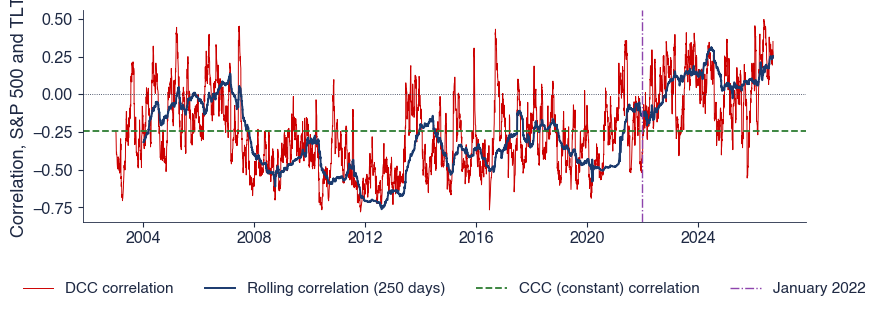

{'spdax': {'ab': 0.9918437311527891,
  'hl': 84.6363193444276,
  'd90': 281.15576707811283},
 'panel': {'ab': 0.9870017229852356,
  'hl': 52.97875226511143,
  'd90': 175.99160558155114},
 'bond': {'ab': 0.9845939926036186,
  'hl': 44.64453581860127,
  'd90': 148.3059378190167},
 'fc': {'10': 0.6964461128247892, '50': 0.6624770908660101},
 'rho': 0.7068243337924999,
 'qbar': 0.5748417597853525,
 'ab_ccc': 0.0}

In [13]:
# Solution
b1 = b1_stock_bond(save_it=False)
a5_half_life(a1, b1)

**Interpretation of the result.** Half of a correlation shock is still there after 85 trading days for the S&P 500 and DAX: diversification returns slowly after a crisis.

# Part B: real data and interpretation

## B1 [Solved]: stocks and US Treasuries

**Question.** Do long Treasuries still hedge stocks, or did the stock-bond correlation change sign after 2022?

1. Fit a GARCH(1,1) to each series and the DCC by two-step maximum likelihood.
2. Test CCC against DCC with the likelihood ratio; compute the half-life.
3. Plot the DCC and the 250-day rolling correlation; report the mean before and after January 2022.
4. Interpretation: what does the change mean for a 60/40 stock-bond portfolio?

**Report:** four parameters with standard errors, one test, one half-life, two means, one sentence.

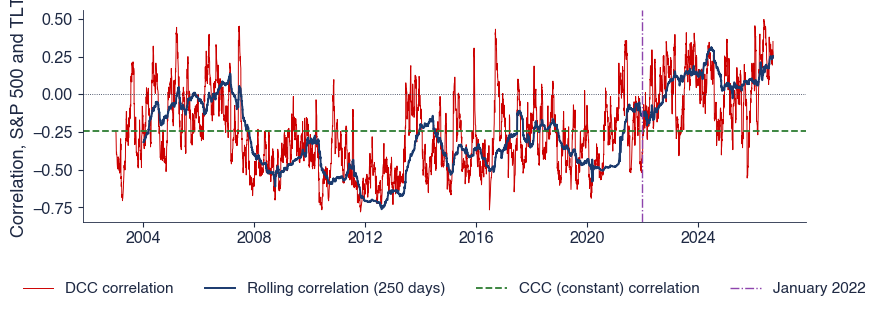

{'n': 5933, 'first': '2003-01-03', 'last': '2026-09-18', 'a': 0.053, 'b': 0.9315, 'se_a': 0.006, 'se_b': 0.0086, 'ab': 0.9846, 'hl': 44.6445, 'lr': 494.4303, 'crit': 5.9915, 'p': 0.0, 'qbar': -0.2438, 'rcorr': -0.2988, 'mean_pre': -0.304, 'mean_post': 0.0398, 'pos_pre': 0.1226, 'pos_post': 0.5929, 'min': -0.7803, 'dmin': '2011-11-02', 'max': 0.4966, 'dmax': '2026-05-21', 'rho_last': 0.3504}


In [14]:
# Solution
b1 = b1_stock_bond(save_it=False)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in b1.items() if k != 'garch'})

**Interpretation of the result.** The correlation was negative on almost every day before 2022 and has been positive on most days since: bonds hedge stocks less than before.

## B2 [Proposed]: a VaR backtest of a BET and DAX portfolio

**Question.** Does a DCC VaR 1% give the right number of violations for a 50/50 BET and DAX portfolio? Model: A3.

1. Compute the VaR 1% with DCC, CCC and the static covariance (parameters 2005-2014, VaR 2015-2026).
2. Count the violations and compare with $0.01n$.
3. Apply the Kupiec and Christoffersen tests.
4. Interpretation: why can the static VaR pass the count and still be a poor risk measure?

**Report:** three counts, three tests, one sentence.

In [ ]:
# Your code here


# Part C: AI critique

## C1 [Proposed]: audit an AI answer

**Context.** An AI assistant answered:

- (a) a full BEKK(1,1) for 10 assets has about as many parameters as a CCC model;
- (b) for the S&P 500 and the DAX, a + b = 0.992, so a correlation shock is gone within a week;
- (c) CCC is DCC with a = b = 0; the LR statistic of 131.8 rejects constant correlation;
- (d) the VaR of a portfolio is the weighted sum of the VaRs of its assets;
- (e) 65 violations of a VaR 1% in 2893 days is close to 1%, so the model is well calibrated;
- (f) the daily correlation of the S&P 500 and the BET is the right input for a weekly risk report.

1. For each statement, say whether it is correct; if not, give the correct statement and the correct number.

**Report:** six verdicts with one line of justification each.

In [ ]:
# Your code here
